# **Reading vs. Seeing**
Resolution, script, and text-priority bias in multi-scale typographic images
Research question. When a large word is made from repeated smaller words that may disagree with it, which concept does a frozen vision-language model associate with the image? Does that answer change with image resolution, the writing system of the small text, and whether the small text is meaningful?

This notebook creates synthetic typographic images and evaluates two pretrained contrastive vision-language models: CLIP ViT-B/32 and SigLIP 2 Base. The large word is always English/Latin; the small repeated fill is Latin or Bengali. Models choose among ten English candidate concepts by image–text similarity.





| Condition | Large shape | Small fill | Purpose |
|---|---|---|---|
| `word` | Concept S | Different concept F | Main conflict condition |
| `same` | Concept S | Same concept S | Congruent control |
| `random` | Concept S | Meaningless strings in the same script | Text-like texture control |
| `solid` | Concept S | Solid dark fill; no small text | No-text baseline |
| `tiled` | No large shape | Repeated word F across the image | Direct word-legibility probe |

In [3]:
!pip -q install -U transformers sentencepiece protobuf scipy
!apt-get -qq update && apt-get -qq install -y fonts-noto-core fonts-dejavu-core libraqm0 libfribidi0 > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [1]:
import os, glob, random, string, math, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw, ImageFont, features
from scipy.stats import spearmanr
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = Path("results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Device: {device}")
print(f"Pillow Raqm text shaping available: {features.check('raqm')}")
if not features.check("raqm"):
    print("WARNING: Bengali shaping may be incorrect. Install libraqm/libfribidi and restart before continuing.")

Python: 3.13.15
PyTorch: 2.11.0+cu130
Device: cuda
Pillow Raqm text shaping available: True


In [18]:
CONCEPTS = ["cat", "dog", "car", "bus", "hat", "cow", "pig", "bee", "fox", "egg"]
BN = {
    "cat": "বিড়াল", "dog": "কুকুর", "car": "গাড়ি", "bus": "বাস",
    "hat": "টুপি", "cow": "গরু", "pig": "শূকর", "bee": "মৌমাছি",
    "fox": "শিয়াল", "egg": "ডিম",
}
SCRIPTS = ["latin", "bengali"]


def find_font(patterns):
    """Return the first installed font matching one of the supplied patterns."""
    for pattern in patterns:
        matches = sorted(glob.glob(pattern, recursive=True))
        if matches:
            return matches[0]
    raise FileNotFoundError(
        "Required font not found. Tried patterns: " + ", ".join(patterns)
    )

LATIN_REGULAR = find_font([
    "/usr/share/fonts/**/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/**/*.ttf"
])
LATIN_BOLD = find_font([
    "/usr/share/fonts/**/DejaVuSans-Bold.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"
])
BENGALI_FONT = find_font([
    "/usr/share/fonts/**/NotoSansBengali-Bold.ttf",
    "/usr/share/fonts/**/NotoSansBengali-Regular.ttf",
    "/usr/share/fonts/**/NotoSansBengali*.ttf",
])

LAYOUT_ENGINE = ImageFont.Layout.RAQM if features.check("raqm") else ImageFont.Layout.BASIC

def load_font(path, size):
    return ImageFont.truetype(path, size=size, layout_engine=LAYOUT_ENGINE)

def word_for(concept_index, script):
    """Get the Latin or Bengali surface form for a concept index."""
    concept = CONCEPTS[int(concept_index)]
    return concept if script == "latin" else BN[concept]

print("Latin font:", LATIN_BOLD)
print("Bengali font:", BENGALI_FONT)
print("Concept/translation pairs:")
for concept in CONCEPTS:
    print(f"  {concept:>3} -> {BN[concept]}")

Latin font: /usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf
Bengali font: /usr/share/fonts/truetype/noto/NotoSansBengali-Bold.ttf
Concept/translation pairs:
  cat -> বিড়াল
  dog -> কুকুর
  car -> গাড়ি
  bus -> বাস
  hat -> টুপি
  cow -> গরু
  pig -> শূকর
  bee -> মৌমাছি
  fox -> শিয়াল
  egg -> ডিম


In [3]:
BASE_SIZE = 672
MODEL_SIZE = 224
STROKE_WIDTH = 10
INK = (20, 20, 20)
RESOLUTIONS = [24, 32, 48, 64, 96, 128, 168, 224]
FILL_FONT_SIZE = 44  # overwritten by the pilot below if a qualifying size is found
_mask_cache = {}


def shape_mask(word, width_fraction=0.94, height_fraction=0.88):
    """Render a centered, bold Latin word into a binary mask."""
    key = (word, width_fraction, height_fraction)
    if key in _mask_cache:
        return _mask_cache[key].copy()

    font = load_font(LATIN_BOLD, 300)
    text = word.upper()
    left, top, right, bottom = font.getbbox(text, stroke_width=STROKE_WIDTH)
    temp = Image.new("L", (right - left, bottom - top), 0)
    draw = ImageDraw.Draw(temp)
    draw.text(
        (-left, -top), text, font=font, fill=255,
        stroke_width=STROKE_WIDTH, stroke_fill=255,
    )
    target_w = int(BASE_SIZE * width_fraction)
    target_h = int(BASE_SIZE * height_fraction)
    temp = temp.resize((target_w, target_h), Image.Resampling.LANCZOS)
    mask = Image.new("L", (BASE_SIZE, BASE_SIZE), 0)
    mask.paste(temp, ((BASE_SIZE - target_w) // 2, (BASE_SIZE - target_h) // 2))
    mask = mask.point(lambda value: 255 if value >= 128 else 0)
    _mask_cache[key] = mask.copy()
    return mask


def fill_layer(text, script, font_size, rng):
    """Tile a repeated word/string over a white canvas using a seeded RNG."""
    font_path = BENGALI_FONT if script == "bengali" else LATIN_BOLD
    font = load_font(font_path, font_size)
    layer = Image.new("RGB", (BASE_SIZE, BASE_SIZE), "white")
    draw = ImageDraw.Draw(layer)
    unit = text + "  "
    unit_width = max(1, int(draw.textlength(unit, font=font)))
    line_height = max(1, int(font_size * 1.45))
    y_start = -rng.randint(0, line_height - 1)

    for row in range(BASE_SIZE // line_height + 3):
        y = y_start + row * line_height
        x = -rng.randint(0, unit_width - 1)
        while x < BASE_SIZE:
            draw.text((x, y), unit, font=font, fill=INK)
            x += unit_width
    return layer


def compose_image(shape_word, fill_text, script, rng, condition="text", font_size=None):
    """Create a typographic image with either text fill or a solid fill."""
    font_size = font_size or FILL_FONT_SIZE
    canvas = Image.new("RGB", (BASE_SIZE, BASE_SIZE), "white")
    if condition == "solid":
        fill = Image.new("RGB", (BASE_SIZE, BASE_SIZE), INK)
    else:
        fill = fill_layer(fill_text, script, font_size, rng)
    canvas.paste(fill, (0, 0), shape_mask(shape_word))
    return canvas

# Bengali consonants and dependent vowel signs for synthetic, non-lexical strings.
BENGALI_CONSONANTS = list("কখগঘচছজঝটঠডঢতথদধনপফবভমযরলশষসহ")
BENGALI_SIGNS = list("ািীুূেৈোৌ")

def random_string(script, rng):
    """Create a short non-word string in the requested script."""
    if script == "latin":
        length = rng.choice([3, 4, 5, 6])
        return "".join(rng.choice(string.ascii_lowercase) for _ in range(length))
    parts = []
    for _ in range(rng.choice([2, 3])):
        part = rng.choice(BENGALI_CONSONANTS)
        if rng.random() < 0.6:
            part += rng.choice(BENGALI_SIGNS)
        parts.append(part)
    return "".join(parts)


def make_resolution_view(image, resolution):
    """Simulate low-resolution input, then return a fixed-size RGB image."""
    small = image.resize((resolution, resolution), Image.Resampling.LANCZOS)
    return small.resize((MODEL_SIZE, MODEL_SIZE), Image.Resampling.BICUBIC)

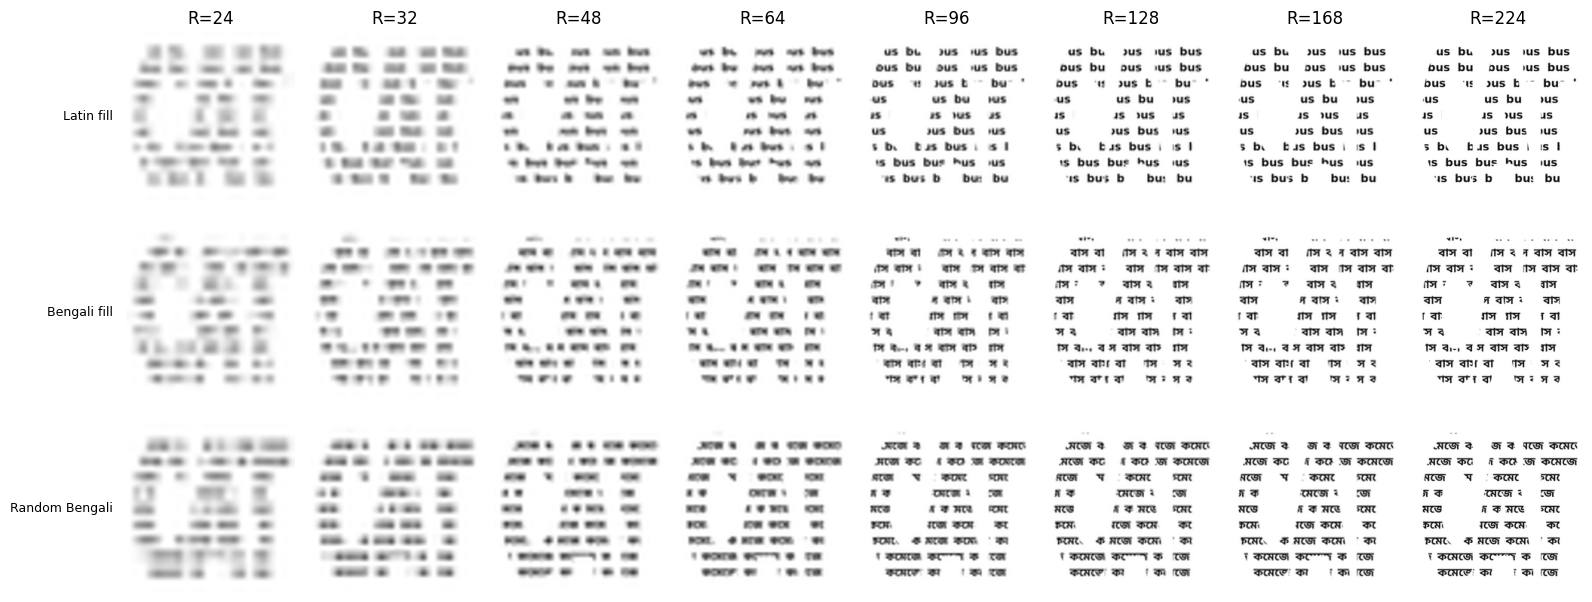

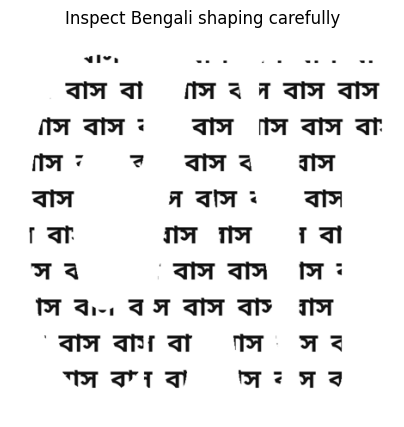

In [4]:
preview_rng = random.Random(2026)
shape_concept = "cat"
fill_concept_index = CONCEPTS.index("bus")
preview_images = [
    ("Latin fill", compose_image(shape_concept, word_for(fill_concept_index, "latin"), "latin", preview_rng)),
    ("Bengali fill", compose_image(shape_concept, word_for(fill_concept_index, "bengali"), "bengali", preview_rng)),
    ("Random Bengali", compose_image(shape_concept, random_string("bengali", preview_rng), "bengali", preview_rng)),
]

fig, axes = plt.subplots(len(preview_images), len(RESOLUTIONS), figsize=(2.0 * len(RESOLUTIONS), 6.3))
for row, (label, base_image) in enumerate(preview_images):
    for col, resolution in enumerate(RESOLUTIONS):
        axes[row, col].imshow(make_resolution_view(base_image, resolution))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"R={resolution}")
    axes[row, 0].text(-0.08, 0.5, label, transform=axes[row, 0].transAxes,
                      ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "examples.png", dpi=150, bbox_inches="tight")
plt.show()

# Large preview for manual Bengali glyph inspection.
plt.figure(figsize=(5, 5))
plt.imshow(preview_images[1][1].resize((448, 448)))
plt.title("Inspect Bengali shaping carefully")
plt.axis("off");
plt.show()

In [5]:
def pooled_features(output):
    """Handle common Hugging Face feature-output formats."""
    if torch.is_tensor(output):
        return output
    if hasattr(output, "pooler_output") and output.pooler_output is not None:
        return output.pooler_output
    if hasattr(output, "image_embeds") and output.image_embeds is not None:
        return output.image_embeds
    if hasattr(output, "text_embeds") and output.text_embeds is not None:
        return output.text_embeds
    raise TypeError(f"Cannot find pooled features in output type {type(output)}")


class ContrastiveScorer:
    """A common interface for image-to-text cosine similarity scoring."""
    def __init__(self, label, model_id, model_kind):
        self.label = label
        self.model_id = model_id
        self.model_kind = model_kind
        self.model = AutoModel.from_pretrained(model_id).to(device).eval()
        self.processor = AutoProcessor.from_pretrained(model_id)
        for parameter in self.model.parameters():
            parameter.requires_grad_(False)

        prompts = [f"a photo of a {concept}" for concept in CONCEPTS]
        tokenized = self.processor(text=prompts, padding=True, truncation=True, return_tensors="pt")
        tokenized = {key: value.to(device) for key, value in tokenized.items()}
        with torch.inference_mode():
            text_features = pooled_features(self.model.get_text_features(**tokenized))
        self.text_features = torch.nn.functional.normalize(text_features, dim=-1)

    @torch.inference_mode()
    def similarities(self, images, batch_size=32):
        """Return an array shaped (number of images, number of concepts)."""
        chunks = []
        for start in range(0, len(images), batch_size):
            batch_images = images[start:start + batch_size]
            pixel_values = self.processor(images=batch_images, return_tensors="pt")["pixel_values"].to(device)
            image_features = pooled_features(self.model.get_image_features(pixel_values=pixel_values))
            image_features = torch.nn.functional.normalize(image_features, dim=-1)
            score_matrix = image_features @ self.text_features.T
            chunks.append(score_matrix.float().cpu().numpy())
        if not chunks:
            return np.empty((0, len(CONCEPTS)), dtype=np.float32)
        return np.concatenate(chunks, axis=0)

MODEL_CONFIGS = {
    "clip-b32": ("openai/clip-vit-base-patch32", "clip"),
    "siglip2-base": ("google/siglip2-base-patch16-224", "siglip2"),
}

# This downloads model weights. Run once per fresh runtime.
scorers = {
    name: ContrastiveScorer(name, model_id, kind)
    for name, (model_id, kind) in MODEL_CONFIGS.items()
}
print("Loaded models:", list(scorers))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Loaded models: ['clip-b32', 'siglip2-base']


In [6]:
PILOT_FONT_SIZES = [32, 40, 48, 56, 72]
pilot_rows = []
clip_scorer = scorers["clip-b32"]

for font_size in PILOT_FONT_SIZES:
    for script in SCRIPTS:
        pilot_images = []
        for concept_index in range(len(CONCEPTS)):
            rng = random.Random(SEED + font_size * 100 + concept_index)
            text = word_for(concept_index, script)
            image = fill_layer(text, script, font_size, rng)
            pilot_images.append(make_resolution_view(image, MODEL_SIZE))
        scores = clip_scorer.similarities(pilot_images)
        accuracy = float((scores.argmax(axis=1) == np.arange(len(CONCEPTS))).mean())
        pilot_rows.append({"font_size": font_size, "script": script, "accuracy": accuracy})

pilot_df = pd.DataFrame(pilot_rows)
latin_qualifying = pilot_df[(pilot_df.script == "latin") & (pilot_df.accuracy >= 0.80)]
if len(latin_qualifying):
    FILL_FONT_SIZE = int(latin_qualifying.sort_values("font_size").iloc[0]["font_size"])
    print("Pilot rule satisfied. Chosen smallest qualifying Latin font size:", FILL_FONT_SIZE)
else:
    FILL_FONT_SIZE = max(PILOT_FONT_SIZES)
    print("WARNING: No tested font size reached 80% Latin tiled accuracy; using largest size:", FILL_FONT_SIZE)

pilot_df.to_csv(OUT_DIR / "pilot_font_size.csv", index=False)
display(pilot_df.pivot(index="font_size", columns="script", values="accuracy").round(3))

Pilot rule satisfied. Chosen smallest qualifying Latin font size: 32


script,bengali,latin
font_size,,
32,0.1,1.0
40,0.1,1.0
48,0.1,1.0
56,0.1,1.0
72,0.2,1.0


In [7]:
N_CONFLICT_REPS = 2
N_RANDOM_REPS = 6
N_TILED_REPS = 3
items = []

for script in SCRIPTS:
    for shape_idx in range(len(CONCEPTS)):
        for fill_idx in range(len(CONCEPTS)):
            condition = "same" if shape_idx == fill_idx else "word"
            for rep in range(N_CONFLICT_REPS):
                items.append({"cond": condition, "script": script, "S": shape_idx,
                              "F": fill_idx, "rep": rep})
        for rep in range(N_RANDOM_REPS):
            items.append({"cond": "random", "script": script, "S": shape_idx,
                          "F": -1, "rep": rep})
    for fill_idx in range(len(CONCEPTS)):
        for rep in range(N_TILED_REPS):
            items.append({"cond": "tiled", "script": script, "S": -1,
                          "F": fill_idx, "rep": rep})
for shape_idx in range(len(CONCEPTS)):
    items.append({"cond": "solid", "script": "none", "S": shape_idx,
                  "F": -1, "rep": 0})

manifest = pd.DataFrame(items)
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
print(f"Base items: {len(manifest)}")
print(f"Image-resolution instances: {len(manifest) * len(RESOLUTIONS)} per model")
display(manifest.groupby(["cond", "script"]).size().rename("items").reset_index())

Base items: 590
Image-resolution instances: 4720 per model


,cond,script,items
0,random,bengali,60
1,random,latin,60
2,same,bengali,20
3,same,latin,20
4,solid,none,10
5,tiled,bengali,30
6,tiled,latin,30
7,word,bengali,180
8,word,latin,180


In [8]:
def render_item(item, item_index):
    """Render one base item with deterministic per-item randomness."""
    rng = random.Random(SEED * 100_000 + item_index)
    condition = item["cond"]
    script = item["script"]
    shape_index = int(item["S"])
    fill_index = int(item["F"])

    if condition == "tiled":
        base_image = fill_layer(word_for(fill_index, script), script, FILL_FONT_SIZE, rng)
    elif condition in ("word", "same"):
        base_image = compose_image(
            CONCEPTS[shape_index], word_for(fill_index, script), script, rng,
            font_size=FILL_FONT_SIZE,
        )
    elif condition == "random":
        base_image = compose_image(
            CONCEPTS[shape_index], random_string(script, rng), script, rng,
            font_size=FILL_FONT_SIZE,
        )
    elif condition == "solid":
        base_image = compose_image(CONCEPTS[shape_index], None, "latin", rng, condition="solid")
    else:
        raise ValueError(f"Unknown condition: {condition}")

    return [make_resolution_view(base_image, resolution) for resolution in RESOLUTIONS]


def run_experiment(model_scorers, manifest_df, item_batch_size=8, image_batch_size=32):
    """Run all models and return one similarity tensor per model."""
    all_scores = {name: [] for name in model_scorers}
    records = manifest_df.to_dict("records")

    for start in tqdm(range(0, len(records), item_batch_size), desc="Rendering/scoring items"):
        stop = min(start + item_batch_size, len(records))
        batch_images = []
        for item_index in range(start, stop):
            batch_images.extend(render_item(records[item_index], item_index))

        for model_name, scorer in model_scorers.items():
            scores = scorer.similarities(batch_images, batch_size=image_batch_size)
            all_scores[model_name].append(scores.reshape(stop - start, len(RESOLUTIONS), len(CONCEPTS)))

    return {name: np.concatenate(chunks, axis=0) for name, chunks in all_scores.items()}

# Main run. For a smoke test, temporarily use manifest.head(5), but do not report it as a full experiment.
similarity_tensors = run_experiment(scorers, manifest)
for model_name, tensor in similarity_tensors.items():
    output_path = OUT_DIR / f"similarities_{model_name}.npy"
    np.save(output_path, tensor)
    print(model_name, tensor.shape, "saved to", output_path)

Rendering/scoring items:   0%|          | 0/74 [00:00<?, ?it/s]

clip-b32 (590, 8, 10) saved to results/similarities_clip-b32.npy
siglip2-base (590, 8, 10) saved to results/similarities_siglip2-base.npy


In [9]:
def make_long_results(tensors, manifest_df):
    rows = []
    records = manifest_df.to_dict("records")
    for model_name, tensor in tensors.items():
        for item_index, item in enumerate(records):
            shape_idx, fill_idx = int(item["S"]), int(item["F"])
            for resolution_index, resolution in enumerate(RESOLUTIONS):
                scores = tensor[item_index, resolution_index]
                prediction = int(np.argmax(scores))
                shape_win = float(prediction == shape_idx) if shape_idx >= 0 else np.nan
                fill_win = float(prediction == fill_idx) if fill_idx >= 0 else np.nan
                margin = np.nan
                if shape_idx >= 0 and fill_idx >= 0 and shape_idx != fill_idx:
                    margin = float(scores[shape_idx] - scores[fill_idx])
                rows.append({
                    "model": model_name, **item, "R": resolution,
                    "pred_index": prediction, "prediction": CONCEPTS[prediction],
                    "shape_win": shape_win, "fill_win": fill_win, "margin": margin,
                })
    return pd.DataFrame(rows)

df = make_long_results(similarity_tensors, manifest)
df.to_csv(OUT_DIR / "long_results.csv", index=False)
print("Long results rows:", len(df))
display(df.head())

Long results rows: 9440


,model,cond,script,S,F,rep,R,pred_index,prediction,shape_win,fill_win,margin
0,clip-b32,same,latin,0,0,0,24,4,hat,0.0,0.0,NaN
1,clip-b32,same,latin,0,0,0,32,4,hat,0.0,0.0,NaN
2,clip-b32,same,latin,0,0,0,48,4,hat,0.0,0.0,NaN
3,clip-b32,same,latin,0,0,0,64,4,hat,0.0,0.0,NaN
4,clip-b32,same,latin,0,0,0,96,0,cat,1.0,1.0,NaN


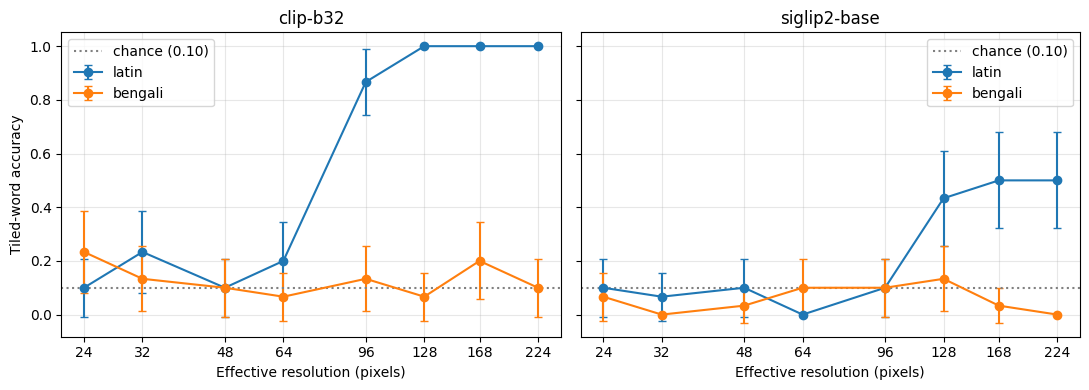

In [10]:
legibility = (df[df.cond == "tiled"]
              .groupby(["model", "script", "R"])["fill_win"]
              .agg(mean="mean", n="count").reset_index())
legibility["se"] = np.sqrt(legibility["mean"] * (1 - legibility["mean"]) / legibility["n"])

fig, axes = plt.subplots(1, len(similarity_tensors), figsize=(5.5 * len(similarity_tensors), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, model_name in zip(axes, similarity_tensors):
    for script in SCRIPTS:
        subset = legibility[(legibility.model == model_name) & (legibility.script == script)]
        ax.errorbar(subset.R, subset["mean"], yerr=1.96 * subset.se,
                    marker="o", capsize=3, label=script)
    ax.axhline(0.10, color="gray", linestyle=":", label="chance (0.10)")
    ax.set_xscale("log", base=2)
    ax.set_xticks(RESOLUTIONS); ax.set_xticklabels(RESOLUTIONS)
    ax.set_title(model_name); ax.set_xlabel("Effective resolution (pixels)")
    ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Tiled-word accuracy")
plt.tight_layout(); plt.savefig(OUT_DIR / "figA_legibility.png", dpi=160); plt.show()

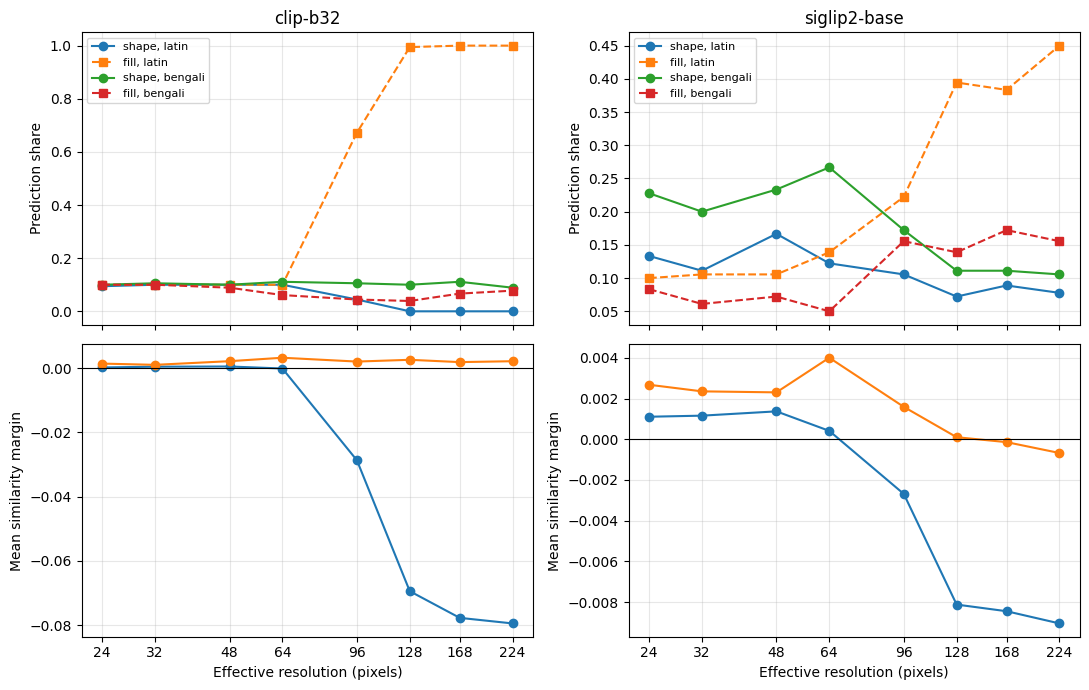

In [11]:
conflict_summary = (df[df.cond == "word"]
    .groupby(["model", "script", "R"])[["shape_win", "fill_win", "margin"]]
    .mean().reset_index())

fig, axes = plt.subplots(2, len(similarity_tensors), figsize=(5.5 * len(similarity_tensors), 7), sharex=True)
axes = np.atleast_2d(axes).reshape(2, len(similarity_tensors))
for col, model_name in enumerate(similarity_tensors):
    for script in SCRIPTS:
        subset = conflict_summary[(conflict_summary.model == model_name) & (conflict_summary.script == script)]
        axes[0, col].plot(subset.R, subset.shape_win, marker="o", label=f"shape, {script}")
        axes[0, col].plot(subset.R, subset.fill_win, marker="s", linestyle="--", label=f"fill, {script}")
        axes[1, col].plot(subset.R, subset.margin, marker="o", label=script)
    axes[0, col].set_title(model_name); axes[0, col].set_ylabel("Prediction share")
    axes[0, col].legend(fontsize=8)
    axes[1, col].axhline(0, color="black", linewidth=0.8)
    axes[1, col].set_ylabel("Mean similarity margin")
    axes[1, col].set_xlabel("Effective resolution (pixels)")
    for row in (0, 1):
        axes[row, col].set_xscale("log", base=2)
        axes[row, col].set_xticks(RESOLUTIONS); axes[row, col].set_xticklabels(RESOLUTIONS)
        axes[row, col].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "figB_shape_vs_fill.png", dpi=160); plt.show()

In [12]:
def first_upward_crossing(resolutions, values, threshold):
    """First upward threshold crossing with linear interpolation in log-resolution."""
    resolutions = np.asarray(resolutions, dtype=float)
    values = np.asarray(values, dtype=float)
    if values[0] >= threshold:
        return float(resolutions[0])
    for i in range(len(values) - 1):
        if values[i] < threshold <= values[i + 1] and values[i + 1] != values[i]:
            fraction = (threshold - values[i]) / (values[i + 1] - values[i])
            return float(np.exp(np.log(resolutions[i]) + fraction * (np.log(resolutions[i + 1]) - np.log(resolutions[i]))))
    return np.nan


def first_shape_to_fill_crossover(resolutions, margins):
    """First positive-to-nonpositive margin crossing; NaN if not observed."""
    resolutions = np.asarray(resolutions, dtype=float)
    margins = np.asarray(margins, dtype=float)
    for i in range(len(margins) - 1):
        if margins[i] > 0 and margins[i + 1] <= 0:
            fraction = margins[i] / (margins[i] - margins[i + 1])
            return float(np.exp(np.log(resolutions[i]) + fraction * (np.log(resolutions[i + 1]) - np.log(resolutions[i]))))
    return np.nan


def bootstrap_interval(matrix, statistic, n_boot=1000, seed=0):
    """Percentile bootstrap interval for a statistic of mean resolution curves."""
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[0] < 2:
        return np.nan, np.nan, 1.0
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        indices = rng.integers(0, matrix.shape[0], size=matrix.shape[0])
        value = statistic(np.nanmean(matrix[indices], axis=0))
        values.append(value)
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]
    if len(valid) < max(20, int(0.5 * n_boot)):
        return np.nan, np.nan, 1 - len(valid) / n_boot
    low, high = np.percentile(valid, [2.5, 97.5])
    return float(low), float(high), float(1 - len(valid) / n_boot)

threshold_rows = []
for model_name in similarity_tensors:
    for script in SCRIPTS:
        conflict = df[(df.model == model_name) & (df.script == script) & (df.cond == "word")]
        margin_wide = conflict.pivot_table(index=["S", "F", "rep"], columns="R", values="margin").reindex(columns=RESOLUTIONS).to_numpy()
        tiled = df[(df.model == model_name) & (df.script == script) & (df.cond == "tiled")]
        legibility_wide = tiled.pivot_table(index=["F", "rep"], columns="R", values="fill_win").reindex(columns=RESOLUTIONS).to_numpy()

        r_star = first_shape_to_fill_crossover(RESOLUTIONS, np.nanmean(margin_wide, axis=0))
        r_star_low, r_star_high, no_cross_share = bootstrap_interval(
            margin_wide, lambda curve: first_shape_to_fill_crossover(RESOLUTIONS, curve), seed=SEED
        )
        r_legible = first_upward_crossing(RESOLUTIONS, np.nanmean(legibility_wide, axis=0), 0.50)
        r_leg_low, r_leg_high, no_leg_share = bootstrap_interval(
            legibility_wide, lambda curve: first_upward_crossing(RESOLUTIONS, curve, 0.50), seed=SEED + 1
        )
        threshold_rows.append({
            "model": model_name, "script": script,
            "R_star": r_star, "R_star_ci_low": r_star_low, "R_star_ci_high": r_star_high,
            "bootstrap_share_without_crossover": no_cross_share,
            "R_legible_50pct": r_legible, "R_legible_ci_low": r_leg_low,
            "R_legible_ci_high": r_leg_high, "bootstrap_share_without_legibility_crossing": no_leg_share,
            "mean_margin_lowest_R": float(np.nanmean(margin_wide, axis=0)[0]),
            "mean_margin_highest_R": float(np.nanmean(margin_wide, axis=0)[-1]),
        })

threshold_summary = pd.DataFrame(threshold_rows).round(3)
threshold_summary.to_csv(OUT_DIR / "summary_thresholds.csv", index=False)
display(threshold_summary)

,model,script,R_star,R_star_ci_low,R_star_ci_high,bootstrap_share_without_crossover,R_legible_50pct,R_legible_ci_low,R_legible_ci_high,bootstrap_share_without_legibility_crossing,mean_margin_lowest_R,mean_margin_highest_R
0,clip-b32,latin,61.402,28.468,65.736,0.218,76.811,71.308,81.996,0.000,0.000,-0.079
1,clip-b32,bengali,NaN,NaN,NaN,0.822,NaN,NaN,NaN,0.995,0.001,0.002
2,siglip2-base,latin,67.534,56.559,76.375,0.000,168.000,118.676,168.000,0.430,0.001,-0.009
3,siglip2-base,bengali,143.071,100.038,217.640,0.242,NaN,NaN,NaN,1.000,0.003,-0.001


clip-b32       latin   : Spearman rho=+0.895, p=4.235e-29, n=80
clip-b32       bengali : Spearman rho=+0.429, p=7.328e-05, n=80
siglip2-base   latin   : Spearman rho=+0.728, p=1.952e-14, n=80
siglip2-base   bengali : Spearman rho=-0.127, p=0.2606, n=80


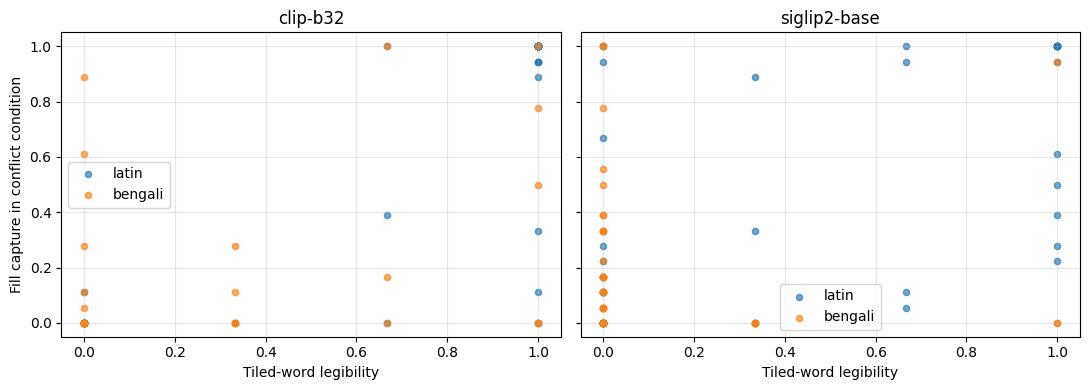

In [13]:
capture = (df[df.cond == "word"]
           .groupby(["model", "script", "F", "R"])["fill_win"].mean().rename("capture"))
legibility_by_word = (df[df.cond == "tiled"]
                      .groupby(["model", "script", "F", "R"])["fill_win"].mean().rename("legibility"))
cells = pd.concat([capture, legibility_by_word], axis=1).dropna().reset_index()

fig, axes = plt.subplots(1, len(similarity_tensors), figsize=(5.5 * len(similarity_tensors), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, model_name in zip(axes, similarity_tensors):
    for script in SCRIPTS:
        subset = cells[(cells.model == model_name) & (cells.script == script)]
        ax.scatter(subset.legibility, subset.capture, s=20, alpha=0.65, label=script)
        if len(subset) >= 3 and subset.legibility.nunique() > 1 and subset.capture.nunique() > 1:
            rho, p_value = spearmanr(subset.legibility, subset.capture)
            print(f"{model_name:14s} {script:8s}: Spearman rho={rho:+.3f}, p={p_value:.4g}, n={len(subset)}")
        else:
            print(f"{model_name:14s} {script:8s}: correlation not estimable")
    ax.set_title(model_name); ax.set_xlabel("Tiled-word legibility")
    ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("Fill capture in conflict condition")
plt.tight_layout(); plt.savefig(OUT_DIR / "figD_legibility_gating.png", dpi=160); plt.show()

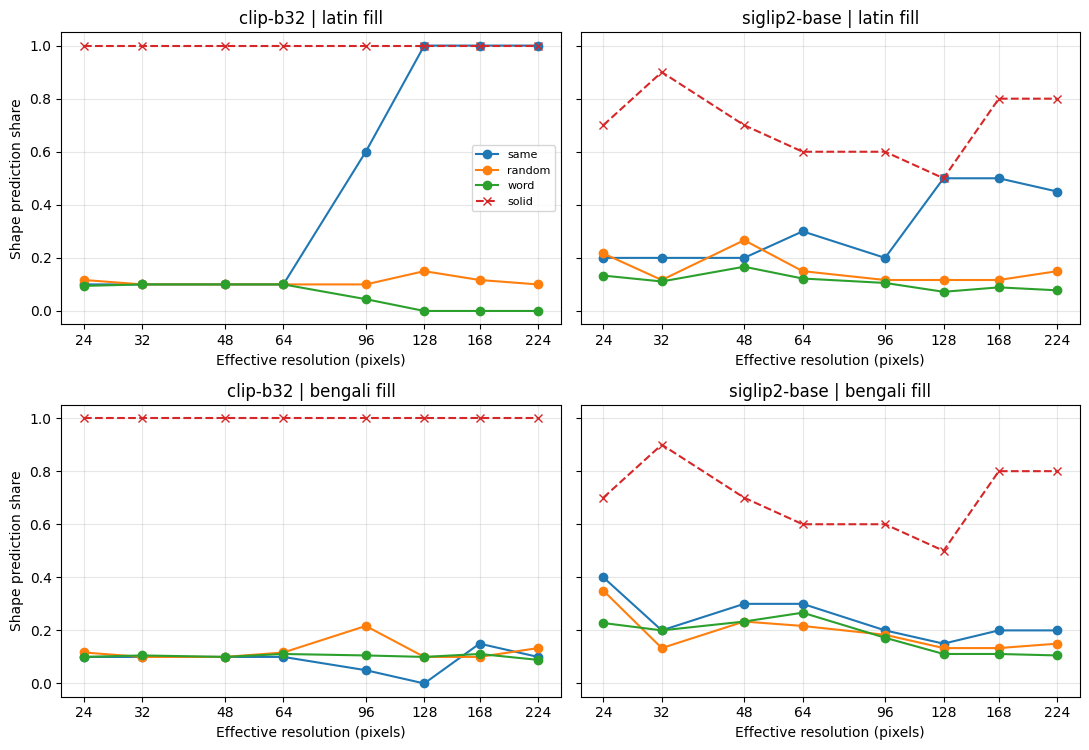

cond                  random   same   word
model        script                       
clip-b32     bengali   0.111  0.083  0.100
             latin     0.122  1.000  0.000
siglip2-base bengali   0.139  0.183  0.109
             latin     0.128  0.483  0.080

In [14]:
condition_summary = (df[df.cond.isin(["word", "random", "same"])]
    .groupby(["model", "script", "cond", "R"])["shape_win"].mean().reset_index())
solid_summary = (df[df.cond == "solid"]
    .groupby(["model", "R"])["shape_win"].mean().reset_index())

fig, axes = plt.subplots(len(SCRIPTS), len(similarity_tensors), figsize=(5.5 * len(similarity_tensors), 3.8 * len(SCRIPTS)), sharey=True)
axes = np.atleast_2d(axes).reshape(len(SCRIPTS), len(similarity_tensors))
for row, script in enumerate(SCRIPTS):
    for col, model_name in enumerate(similarity_tensors):
        ax = axes[row, col]
        for condition in ["same", "random", "word"]:
            subset = condition_summary[(condition_summary.model == model_name) &
                                       (condition_summary.script == script) &
                                       (condition_summary.cond == condition)]
            ax.plot(subset.R, subset.shape_win, marker="o", label=condition)
        baseline = solid_summary[solid_summary.model == model_name]
        ax.plot(baseline.R, baseline.shape_win, linestyle="--", marker="x", label="solid")
        ax.set_title(f"{model_name} | {script} fill")
        ax.set_xscale("log", base=2); ax.set_xticks(RESOLUTIONS); ax.set_xticklabels(RESOLUTIONS)
        ax.set_xlabel("Effective resolution (pixels)"); ax.grid(alpha=0.3)
        if col == 0: ax.set_ylabel("Shape prediction share")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "figE_reading_vs_texture.png", dpi=160); plt.show()

high_resolution_summary = (condition_summary[condition_summary.R >= 128]
    .groupby(["model", "script", "cond"])["shape_win"].mean().unstack("cond").round(3))
high_resolution_summary.to_csv(OUT_DIR / "high_resolution_condition_summary.csv")
display(high_resolution_summary)

In [15]:
run_info = {
    "project": "Reading vs. Seeing",
    "seed": SEED,
    "device": device,
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": __import__("transformers").__version__,
    "pillow_version": __import__("PIL").__version__,
    "models": {name: model_id for name, (model_id, _) in MODEL_CONFIGS.items()},
    "concepts": CONCEPTS,
    "bengali_translations": BN,
    "scripts": SCRIPTS,
    "resolutions": RESOLUTIONS,
    "fill_font_size_selected_by_pilot": FILL_FONT_SIZE,
    "pilot_rule": "Smallest tested font size where CLIP Latin tiled-word accuracy >= 0.80 at 224 px; otherwise largest tested size.",
    "base_items": int(len(manifest)),
    "images_per_model": int(len(manifest) * len(RESOLUTIONS)),
    "warning": "Synthetic benchmark; inspect Bengali rendering and interpret results as model/setup-specific.",
}
with open(OUT_DIR / "run_info.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, ensure_ascii=False, indent=2)

print("Experiment outputs saved under:", OUT_DIR.resolve())
for path in sorted(OUT_DIR.iterdir()):
    print(f"{path.name:42s} {path.stat().st_size:>12,} bytes")

Experiment outputs saved under: /content/results
examples.png                                    867,325 bytes
figA_legibility.png                              87,378 bytes
figB_shape_vs_fill.png                          176,248 bytes
figD_legibility_gating.png                       59,935 bytes
figE_reading_vs_texture.png                     181,240 bytes
high_resolution_condition_summary.csv               167 bytes
long_results.csv                                564,099 bytes
manifest.csv                                     11,120 bytes
pilot_font_size.csv                                 166 bytes
run_info.json                                     1,241 bytes
similarities_clip-b32.npy                       188,928 bytes
similarities_siglip2-base.npy                   188,928 bytes
summary_thresholds.csv                              498 bytes


In [16]:
import os

print("Current directory:", os.getcwd())
print(os.listdir("/content"))

Current directory: /content
['.config', 'results', 'sample_data']


In [20]:
import os
import shutil

PROJECT_DIR = "/content/reading-vs-seeing"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Change these paths if your uploaded files are elsewhere.
try:
    shutil.copy(
        "/content/reading_vs_seeing_rewritten.ipynb",
        f"{PROJECT_DIR}/reading_vs_seeing.ipynb"
    )
    print("Successfully copied notebook file.")
except FileNotFoundError:
    print("Note: /content/reading_vs_seeing_rewritten.ipynb not found. Please upload it if you need it.")

try:
    shutil.copy(
        "/content/README_reading_vs_seeing.md",
        f"{PROJECT_DIR}/README.md"
    )
    print("Successfully copied README file.")
except FileNotFoundError:
    print("Note: /content/README_reading_vs_seeing.md not found. Please upload it if you need it.")

with open(f"{PROJECT_DIR}/.gitignore", "w") as f:
    f.write(
        "__pycache__/\n"
        ".ipynb_checkpoints/\n"
        ".venv/\n"
        "venv/\n"
        ".env\n"
        "results/*.npy\n"
    )

print("Project directory contents:", os.listdir(PROJECT_DIR))

Note: /content/reading_vs_seeing_rewritten.ipynb not found. Please upload it if you need it.
Note: /content/README_reading_vs_seeing.md not found. Please upload it if you need it.
Project directory contents: ['.gitignore']


In [21]:
%cd /content/reading-vs-seeing

!git init -b main
!git config user.name "MalihaKaisar"
!git config user.email "malihakaisar100@gmail.com"
!git add README.md reading_vs_seeing.ipynb .gitignore
!git commit -m "Add documented reading vs seeing experiment"

/content/reading-vs-seeing
Initialized empty Git repository in /content/reading-vs-seeing/.git/
fatal: pathspec 'README.md' did not match any files
On branch main

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore

nothing added to commit but untracked files present (use "git add" to track)


In [23]:
from getpass import getpass

token = getpass("Paste your GitHub token (input is hidden): ")
username = input("GitHub username: ")
repo_name = "reading-vs-seeing"

remote_url = f"https://github.com/{username}/{repo_name}.git"

!git remote add origin {remote_url}

Paste your GitHub token (input is hidden): ··········
GitHub username: MalihaKaisar


In [24]:
import subprocess
import os

env = os.environ.copy()
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    input=f"{username}\n{token}\n",
    text=True,
    capture_output=True,
    env=env
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
else:
    print("Push completed successfully!")

token = None


error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/MalihaKaisar/reading-vs-seeing.git'



In [25]:
%cd /content/reading-vs-seeing

!git add README.md reading_vs_seeing.ipynb
!git commit -m "Update experiment and documentation"
!git push

/content/reading-vs-seeing
fatal: pathspec 'README.md' did not match any files
On branch main

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore

nothing added to commit but untracked files present (use "git add" to track)
fatal: The current branch main has no upstream branch.
To push the current branch and set the remote as upstream, use

    git push --set-upstream origin main

To have this happen automatically for branches without a tracking
upstream, see 'push.autoSetupRemote' in 'git help config'.



In [26]:
import os

print("Current directory files:")
print(os.listdir("/content"))

print("\nRepository files:")
print(os.listdir("/content/reading-vs-seeing"))

Current directory files:
['.config', 'results', 'reading-vs-seeing', 'sample_data']

Repository files:
['.git', '.gitignore']


In [27]:
import os
import shutil

repo = "/content/reading-vs-seeing"
os.makedirs(repo, exist_ok=True)

# Update these filenames if Step 1 shows different names
notebook_source = "/content/reading_vs_seeing_rewritten.ipynb"
readme_source = "/content/README_reading_vs_seeing.md"

if os.path.exists(notebook_source):
    shutil.copy2(notebook_source, f"{repo}/reading_vs_seeing.ipynb")
else:
    print("Notebook not found:", notebook_source)

if os.path.exists(readme_source):
    shutil.copy2(readme_source, f"{repo}/README.md")
else:
    print("README not found:", readme_source)

print("Repository now contains:", os.listdir(repo))

Notebook not found: /content/reading_vs_seeing_rewritten.ipynb
README not found: /content/README_reading_vs_seeing.md
Repository now contains: ['.git', '.gitignore']


In [28]:
import os

for root, dirs, files in os.walk("/content"):
    # Skip Git internals to keep the output short
    dirs[:] = [d for d in dirs if d != ".git"]

    for filename in files:
        if filename.endswith((".ipynb", ".md")):
            print(os.path.join(root, filename))

/content/sample_data/README.md


In [ ]:
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))